# CIFAR-100: the CIFAR-10 recipe on 100 classes

Same pipeline as the CIFAR-10 notebook, now with **100 classes** (600 images each: 500 train / 100 test).
This notebook is **self-contained** (no local imports): upload it to Kaggle or Colab, switch on a GPU and *Run all*.
It picks the device automatically: CUDA (Kaggle T4/P100, Colab) → full-width ResNet-9; Apple MPS / CPU → half width
so it fits on a laptop. The saved outputs below were produced on: Apple M4 laptop GPU (MPS) in Low Power Mode, half-width ResNet-9 (1.68 M parameters), 20 epochs per model; on a Kaggle/Colab GPU the notebook automatically uses full width and 30 epochs.

Compared models (both with the same augmentation and validation protocol):
1. `deep_cnn` — a reference deep CNN (Adam 1e-3), as a baseline;
2. `resnet9` — ResNet-9 + SE attention + OneCycle + label smoothing (best CIFAR-10 recipe).

In [1]:
import io, time, os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from IPython.display import display

SEED = 42; torch.manual_seed(SEED); rng = np.random.default_rng(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
ON_CUDA = DEVICE.type == "cuda"
WIDTH = 64 if ON_CUDA else 32          # ResNet-9 channels: full width on a cloud GPU, half on a laptop
EPOCHS = 30 if ON_CUDA else 20   # laptop run is shorter
OUT = Path("cifar100_outputs"); OUT.mkdir(exist_ok=True)
print("torch", torch.__version__, "| device:", DEVICE, "| ResNet-9 width:", WIDTH)

torch 2.14.1 | device: mps | ResNet-9 width: 32


## 1. Data

In [2]:
def load_cifar100():
    """Local parquet mirror (this repo) if present, otherwise the official archive via torchvision (Kaggle/Colab)."""
    local = Path("../data/raw/hf_cifar100")
    if (local / "train.parquet").exists():
        from PIL import Image
        def dec(df):
            x = np.stack([np.array(Image.open(io.BytesIO(r["bytes"])).convert("RGB")) for r in df["img"]])
            return x, df["fine_label"].to_numpy(np.int64), df["coarse_label"].to_numpy(np.int64)
        tr, te = dec(pd.read_parquet(local / "train.parquet")), dec(pd.read_parquet(local / "test.parquet"))
    else:
        import torchvision, pickle
        torchvision.datasets.CIFAR100("data", train=True, download=True)
        def unpickle(f):
            d = pickle.load(open(f"data/cifar-100-python/{f}", "rb"), encoding="latin1")
            return d["data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1), np.array(d["fine_labels"]), np.array(d["coarse_labels"])
        tr, te = unpickle("train"), unpickle("test")
    return tr, te

(x_train_full, y_train_full, c_train_full), (x_test, y_test, c_test) = load_cifar100()
FINE = ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider', 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor', 'train', 'trout', 'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm']
COARSE = ['aquatic_mammals', 'fish', 'flowers', 'food_containers', 'fruit_and_vegetables', 'household_electrical_devices', 'household_furniture', 'insects', 'large_carnivores', 'large_man-made_outdoor_things', 'large_natural_outdoor_scenes', 'large_omnivores_and_herbivores', 'medium_mammals', 'non-insect_invertebrates', 'people', 'reptiles', 'small_mammals', 'trees', 'vehicles_1', 'vehicles_2']
print("train", x_train_full.shape, "test", x_test.shape, "| fine classes:", len(np.unique(y_train_full)), "| superclasses:", len(np.unique(c_train_full)))

train (50000, 32, 32, 3) test (10000, 32, 32, 3) | fine classes: 100 | superclasses: 20


### 1.1 Preview and class distribution
**Expectation:** 500 train / 100 test per fine class; 20 superclasses with 5 fine classes each; many visually close classes (maple/oak/willow tree, boy/girl/man/woman).

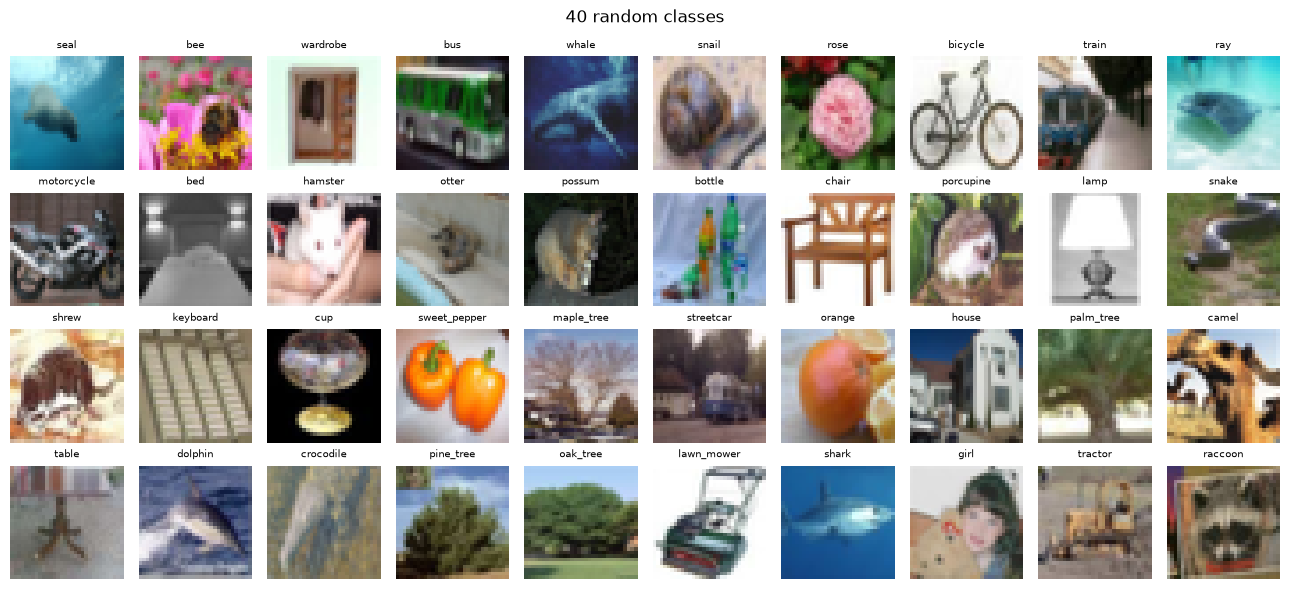

train per class: min 500 max 500 | test per class: min 100 max 100


,superclass,fine classes
0,aquatic_mammals,"beaver, dolphin, otter, seal, whale"
1,fish,"aquarium_fish, flatfish, ray, shark, trout"
2,flowers,"orchid, poppy, rose, sunflower, tulip"
3,food_containers,"bottle, bowl, can, cup, plate"
4,fruit_and_vegetables,"apple, mushroom, orange, pear, sweet_pepper"
5,household_electrical_devices,"clock, keyboard, lamp, telephone, television"
6,household_furniture,"bed, chair, couch, table, wardrobe"
7,insects,"bee, beetle, butterfly, caterpillar, cockroach"
8,large_carnivores,"bear, leopard, lion, tiger, wolf"
9,large_man-made_outdoor_things,"bridge, castle, house, road, skyscraper"


In [3]:
fig, axes = plt.subplots(4, 10, figsize=(13, 6))
for ax, c in zip(axes.flat, rng.choice(100, 40, replace=False)):
    i = rng.choice(np.where(y_train_full == c)[0]); ax.imshow(x_train_full[i]); ax.set_title(FINE[c], fontsize=7.5); ax.axis("off")
plt.suptitle("40 random classes"); plt.tight_layout(); plt.savefig(OUT / "preview.png"); plt.show()

counts = pd.Series(np.bincount(y_train_full)); tcounts = pd.Series(np.bincount(y_test))
print("train per class: min", counts.min(), "max", counts.max(), "| test per class: min", tcounts.min(), "max", tcounts.max())
sup = pd.DataFrame({"superclass": COARSE, "fine classes": [", ".join(sorted({FINE[f] for f in np.unique(y_train_full[c_train_full == k])})) for k in range(20)]})
display(sup)

Perfectly balanced again, but only **500 training images per class** (10× fewer than CIFAR-10) for 10× more classes. Random guessing gives 1%. Expect strong overfitting without augmentation and a much lower accuracy than on CIFAR-10. Because of fine-grained classes, **top-5 accuracy** and superclass accuracy are reported too.

## 2. Preprocessing
Stratified 45 000 / 5 000 train/validation split, per-channel standardisation fitted on train, on-the-fly augmentation (random crop with 4 px reflect padding + horizontal flip).

In [4]:
from sklearn.model_selection import train_test_split
x_tr, x_va, y_tr, y_va = train_test_split(x_train_full, y_train_full, test_size=5000, stratify=y_train_full, random_state=SEED)
mean = (x_tr / 255).mean((0, 1, 2)); std = (x_tr / 255).std((0, 1, 2))
def to_t(x):
    t = torch.from_numpy(x).to(DEVICE).permute(0, 3, 1, 2).float() / 255
    return (t - torch.tensor(mean, device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)) / torch.tensor(std, device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)
X = {"train": to_t(x_tr), "val": to_t(x_va), "test": to_t(x_test)}
Y = {"train": torch.from_numpy(y_tr).to(DEVICE), "val": torch.from_numpy(y_va).to(DEVICE), "test": torch.from_numpy(y_test).to(DEVICE)}
print({k: tuple(v.shape) for k, v in X.items()}, "| mean", mean.round(3), "std", std.round(3))

def augment(x, pad=4):
    b, c, h, w = x.shape
    xp = F.pad(x, (pad,) * 4, mode="reflect")
    dy = torch.randint(0, 2 * pad + 1, (b,), device=x.device); dx = torch.randint(0, 2 * pad + 1, (b,), device=x.device)
    rows = (dy[:, None] + torch.arange(h, device=x.device))[:, :, None]; cols = (dx[:, None] + torch.arange(w, device=x.device))[:, None, :]
    out = xp.permute(0, 2, 3, 1)[torch.arange(b, device=x.device)[:, None, None], rows, cols].permute(0, 3, 1, 2)
    flip = torch.rand(b, device=x.device) < 0.5; out[flip] = out[flip].flip(3)
    return out.contiguous()

{'train': (45000, 3, 32, 32), 'val': (5000, 3, 32, 32), 'test': (10000, 3, 32, 32)} | mean [0.507 0.486 0.441] std [0.267 0.256 0.276]


/var/folders/j8/9ybn32z5657fsgsg26zkqsqr0000gn/T/ipykernel_12683/4039076709.py:8: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  Y = {"train": torch.from_numpy(y_tr).to(DEVICE), "val": torch.from_numpy(y_va).to(DEVICE), "test": torch.from_numpy(y_test).to(DEVICE)}


## 3. Models
Baseline deep CNN and ResNet-9 with SE blocks — same definitions as `src/models.py` of the CIFAR-10 study.

In [5]:
class SEBlock(nn.Module):
    def __init__(self, c, ratio=8):
        super().__init__()
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c, c // ratio), nn.ReLU(), nn.Linear(c // ratio, c), nn.Sigmoid())
    def forward(self, x): return x * self.fc(x)[:, :, None, None]

class BaselineDeepCNN(nn.Module):
    def __init__(self, n=100):
        super().__init__()
        L, c_in = [], 3
        for c, p in zip([32, 64, 128], [0.25, 0.3, 0.4]):
            L += [nn.Conv2d(c_in, c, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(c), nn.Conv2d(c, c, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(c), nn.MaxPool2d(2), nn.Dropout(p)]
            c_in = c
        self.features = nn.Sequential(*L)
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128 * 16, 256), nn.ReLU(), nn.BatchNorm1d(256), nn.Dropout(0.5), nn.Linear(256, n))
    def forward(self, x): return self.head(self.features(x))

def cbr(i, o, pool=False):
    L = [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)]
    return nn.Sequential(*(L + [nn.MaxPool2d(2)] if pool else L))

class Residual(nn.Module):
    def __init__(self, c):
        super().__init__(); self.body = nn.Sequential(cbr(c, c), cbr(c, c)); self.se = SEBlock(c, 16)
    def forward(self, x): return x + self.se(self.body(x))

class ResNet9(nn.Module):
    def __init__(self, n=100, w=64):
        super().__init__()
        self.net = nn.Sequential(cbr(3, w), cbr(w, 2 * w, True), Residual(2 * w), cbr(2 * w, 4 * w, True), cbr(4 * w, 8 * w, True),
                                 Residual(8 * w), nn.AdaptiveMaxPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(8 * w, n))
    def forward(self, x): return self.net(x)

for name, m in [("deep_cnn", BaselineDeepCNN()), ("resnet9", ResNet9(w=WIDTH))]:
    print(f"{name:9s} params = {sum(p.numel() for p in m.parameters()):,}")

deep_cnn  params = 838,660
resnet9   params = 1,678,296


## 4. Training
Best epoch chosen on validation accuracy; test evaluated once at the end. Top-5 accuracy = true class among the 5 highest scores.

In [6]:
@torch.no_grad()
def logits_of(model, x, bs=1000):
    model.eval(); return torch.cat([model(x[i:i + bs]) for i in range(0, len(x), bs)])

def metrics(logits, y):
    top5 = logits.topk(5, 1).indices
    return {"loss": F.cross_entropy(logits, y).item(), "acc": (logits.argmax(1) == y).float().mean().item(),
            "top5": (top5 == y[:, None]).any(1).float().mean().item()}

def train(name, model, opt_kind, epochs=EPOCHS, bs=128, lr=1e-3, smoothing=0.0):
    torch.manual_seed(SEED); model = model.to(DEVICE)
    n = len(Y["train"]); steps = (n + bs - 1) // bs
    if opt_kind == "adam":
        opt, sched = torch.optim.Adam(model.parameters(), lr=lr), None
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=5e-4)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs, steps_per_epoch=steps, pct_start=0.25)
    crit = nn.CrossEntropyLoss(label_smoothing=smoothing); hist, best, best_state = [], -1, None; t_start = time.time()
    for ep in range(1, epochs + 1):
        model.train(); order = torch.randperm(n, device=DEVICE); tl = tc = 0.0; t0 = time.time()
        for i in range(steps):
            idx = order[i * bs:(i + 1) * bs]; xb, yb = augment(X["train"][idx]), Y["train"][idx]
            out = model(xb); loss = crit(out, yb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            if sched: sched.step()
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item()
        v = metrics(logits_of(model, X["val"]), Y["val"])
        hist.append({"epoch": ep, "train_loss": tl / n, "train_acc": tc / n, "val_loss": v["loss"], "val_acc": v["acc"], "val_top5": v["top5"], "sec": time.time() - t0})
        if v["acc"] > best: best, best_state = v["acc"], {k: t.clone() for k, t in model.state_dict().items()}
        if ep % 5 == 0 or ep == 1: print(f"[{name}] ep {ep:2d} train acc {tc / n:.3f} | val acc {v['acc']:.3f} top5 {v['top5']:.3f} | {hist[-1]['sec']:.0f}s", flush=True)
    model.load_state_dict(best_state); torch.save(best_state, OUT / f"{name}.pt")
    te = metrics(logits_of(model, X["test"]), Y["test"])
    h = pd.DataFrame(hist); h.to_csv(OUT / f"{name}_history.csv", index=False)
    return model, h, {"model": name, "params": sum(p.numel() for p in model.parameters()), "best_val_acc": best,
                      "final_train_acc": h.train_acc.iloc[-1], "test_acc": te["acc"], "test_top5": te["top5"], "test_loss": te["loss"],
                      "minutes": (time.time() - t_start) / 60}

RES = {}
RES["deep_cnn"] = train("deep_cnn", BaselineDeepCNN(), "adam", lr=1e-3)
RES["resnet9"] = train("resnet9", ResNet9(w=WIDTH), "sgd_onecycle", lr=0.1, smoothing=0.1)

[deep_cnn] ep  1 train acc 0.110 | val acc 0.204 top5 0.501 | 26s


[deep_cnn] ep  5 train acc 0.345 | val acc 0.438 top5 0.754 | 25s


[deep_cnn] ep 10 train acc 0.431 | val acc 0.515 top5 0.822 | 25s


[deep_cnn] ep 15 train acc 0.470 | val acc 0.546 top5 0.841 | 25s


[deep_cnn] ep 20 train acc 0.502 | val acc 0.575 top5 0.855 | 23s


[resnet9] ep  1 train acc 0.110 | val acc 0.198 top5 0.469 | 41s


[resnet9] ep  5 train acc 0.447 | val acc 0.425 top5 0.737 | 48s


[resnet9] ep 10 train acc 0.579 | val acc 0.504 top5 0.808 | 51s


[resnet9] ep 15 train acc 0.671 | val acc 0.599 top5 0.859 | 48s


[resnet9] ep 20 train acc 0.818 | val acc 0.696 top5 0.913 | 51s


,params,best_val_acc,final_train_acc,test_acc,test_top5,test_loss,minutes
model,,,,,,,
deep_cnn,838660,0.5748,0.5022,0.5756,0.8580,1.4971,8.3755
resnet9,1678296,0.6956,0.8183,0.6958,0.9148,1.1580,15.9031


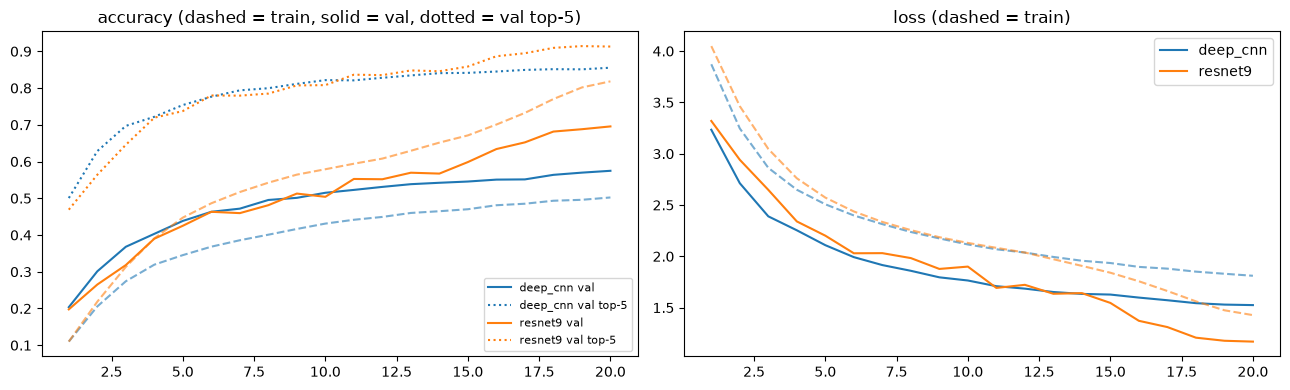

In [7]:
summary = pd.DataFrame([r[2] for r in RES.values()]).set_index("model"); summary.to_csv(OUT / "summary.csv"); display(summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (name, (_, h, _)) in enumerate(RES.items()):
    axes[0].plot(h.epoch, h.train_acc, f"C{i}--", alpha=0.6); axes[0].plot(h.epoch, h.val_acc, f"C{i}", label=f"{name} val"); axes[0].plot(h.epoch, h.val_top5, f"C{i}:", label=f"{name} val top-5")
    axes[1].plot(h.epoch, h.train_loss, f"C{i}--", alpha=0.6); axes[1].plot(h.epoch, h.val_loss, f"C{i}", label=name)
axes[0].set_title("accuracy (dashed = train, solid = val, dotted = val top-5)"); axes[1].set_title("loss (dashed = train)"); axes[0].legend(fontsize=8); axes[1].legend()
plt.tight_layout(); plt.savefig(OUT / "curves.png"); plt.show()

| Model | Params | Val acc | Test top-1 | Test top-5 | Test loss |
|---|---|---|---|---|---|
| Baseline deep CNN | 0.84 M | 57.5% | 57.6% | 85.8% | 1.50 |
| ResNet-9 + SE | 1.68 M | 69.6% | **69.6%** | **91.5%** | 1.16 |

ResNet-9 is **+12 pp** better in top-1. With 100 classes the baseline CNN is clearly *under*fitting rather than overfitting: train accuracy (50%, measured with dropout and augmentation) stays below validation, and its curve flattens after ~12 epochs — 0.8 M parameters and heavy dropout (up to 0.5) are too little capacity for 100 classes. ResNet-9 keeps rising until the end (the OneCycle lr decay in the last third adds ~12 pp), and its train accuracy (82%) is now above validation: it uses its capacity. Both would gain from more epochs. Top-5 accuracy is far higher (91.5%): the correct class is almost always among the candidates, the hard part is choosing between similar fine classes.

## 5. Error analysis of ResNet-9

fine accuracy 0.6958 | superclass of the prediction correct: 0.8027
of the wrong predictions, 35.1% stay inside the true superclass


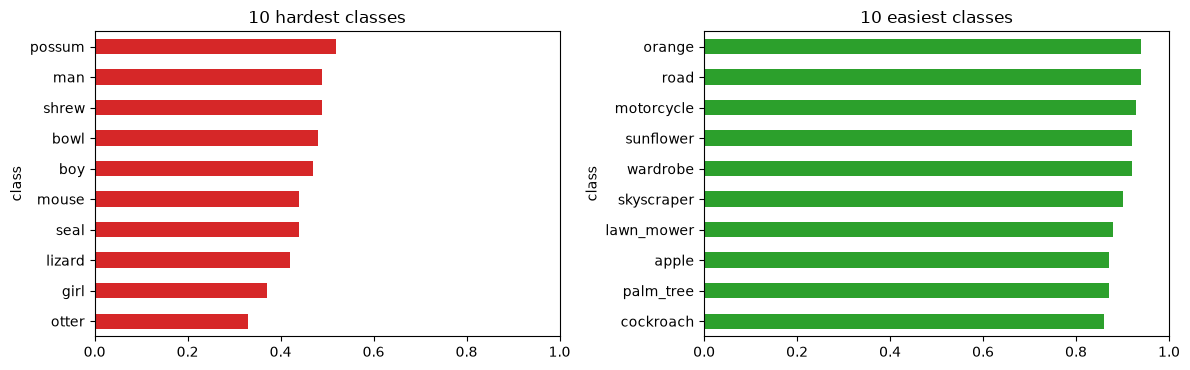

,true,predicted,count
0,maple_tree,oak_tree,22
1,girl,woman,20
2,woman,girl,17
3,boy,girl,16
4,otter,seal,16
5,bowl,plate,15
6,dolphin,whale,15
7,worm,snake,15
8,pine_tree,oak_tree,14
9,bus,streetcar,14


In [8]:
model = RES["resnet9"][0]; lg = logits_of(model, X["test"]); pred = lg.argmax(1).cpu().numpy()
coarse_of = {f: c for f, c in zip(y_train_full, c_train_full)}
pc = pd.DataFrame({"class": FINE, "accuracy": [(pred[y_test == k] == k).mean() for k in range(100)]}).sort_values("accuracy")
super_acc = np.mean([coarse_of[p] == coarse_of[t] for p, t in zip(pred, y_test)])
print(f"fine accuracy {np.mean(pred == y_test):.4f} | superclass of the prediction correct: {super_acc:.4f}")
print(f"of the wrong predictions, {np.mean([coarse_of[p] == coarse_of[t] for p, t in zip(pred, y_test) if p != t]):.1%} stay inside the true superclass")
pc.to_csv(OUT / "per_class_accuracy.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
pc.head(10).plot.barh(x="class", y="accuracy", ax=axes[0], legend=False, color="C3", title="10 hardest classes")
pc.tail(10).plot.barh(x="class", y="accuracy", ax=axes[1], legend=False, color="C2", title="10 easiest classes")
for ax in axes: ax.set_xlim(0, 1)
plt.tight_layout(); plt.savefig(OUT / "per_class.png"); plt.show()
from collections import Counter
conf = Counter((FINE[t], FINE[p]) for t, p in zip(y_test, pred) if t != p).most_common(10)
display(pd.DataFrame([(a, b, n) for (a, b), n in conf], columns=["true", "predicted", "count"]))

Hardest classes: otter (33%), girl (37%), lizard (42%), seal and mouse (44%); easiest: orange, road (94%), motorcycle (93%), sunflower (92%). The top confusions are *semantically* close pairs: maple ↔ oak ↔ pine tree, girl ↔ woman ↔ boy, otter → seal, dolphin → whale, bowl → plate, bus → streetcar. **35% of all errors stay inside the true superclass** (if errors were random, ~4% would), and the superclass of the prediction is right in 80% of cases. So the network learns the coarse hierarchy well; what is missing at 32×32 is the fine detail that separates a girl from a woman or a maple from an oak.

## 6. Conclusion

1. CIFAR-100 has the same images as CIFAR-10 in format, but 100 classes with only 500 training images each, so it is much harder: chance is 1%.
2. The baseline deep CNN reaches **57.6%** top-1 / 85.8% top-5 and underfits; the CIFAR-10 recipe (ResNet-9 + SE, augmentation, OneCycle, label smoothing) reaches **69.6%** top-1 / **91.5%** top-5 with the same 20 epochs.
3. Errors are mostly between semantically close classes (trees, people, aquatic mammals): 35% of mistakes stay in the true superclass.
4. On a cloud GPU (Kaggle/Colab) the same notebook runs the full-width ResNet-9 for 30 epochs, which usually adds several more points (published ResNet-9-type results are ~75%).